# Step 08 — Hyperparameter Tuning

This notebook optimizes the machine learning models developed for predicting employability from competence constructs.

The selected predictors are:

- Life & Career Skills
- Learning & Innovation Skills
- Information Technology & Media Skills

The target variable is the overall Employability Score (`EVS_avg`).

Hyperparameter tuning is performed only on the training dataset using cross-validation. The held-out test dataset is used only after tuning to provide an unbiased evaluation of model performance.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

from xgboost import XGBRegressor

import joblib

In [3]:
PROJECT_DIR = Path.cwd()

# If notebook is inside notebooks/phase2_competence
if PROJECT_DIR.name == "phase2_competence":
    PROJECT_DIR = PROJECT_DIR.parent.parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "phase2_competence_prepared.csv"
)

RESULT_DIR = (
    PROJECT_DIR
    / "reports"
    / "phase2"
    / "hyperparameter_tuning"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project directory:", PROJECT_DIR)
print("Dataset:", DATA_PATH)
print("Results:", RESULT_DIR)

Project directory: d:\internship-employability-project
Dataset: d:\internship-employability-project\data\processed\phase2_competence_prepared.csv
Results: d:\internship-employability-project\reports\phase2\hyperparameter_tuning


In [4]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


Define Final Features and Target

In [5]:
FEATURES = [
    "LifeCareer_avg",
    "LearningInnovation_avg",
    "ITMedia_avg"
]

TARGET = "EVS_avg"

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['LifeCareer_avg', 'LearningInnovation_avg', 'ITMedia_avg']

X shape: (1000, 3)
y shape: (1000,)


In [6]:
print("Missing values in features:")
print(X.isnull().sum())

print("\nMissing target values:")
print(y.isnull().sum())

Missing values in features:
LifeCareer_avg            0
LearningInnovation_avg    0
ITMedia_avg               0
dtype: int64

Missing target values:
0


Create Training and Test Sets

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


efine Cross-Validation Strategy

In [8]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

KFold(n_splits=5, random_state=42, shuffle=True)


Establish Untuned Baselines

In [9]:
baseline_models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Random Forest": RandomForestRegressor(
        random_state=42
    ),

    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR())
    ]),

    "XGBoost": XGBRegressor(
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    )
}

In [10]:
baseline_cv_results = []

for name, model in baseline_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="r2",
        n_jobs=-1
    )

    baseline_cv_results.append({
        "Model": name,
        "Mean_CV_R2": scores.mean(),
        "Std_CV_R2": scores.std()
    })

baseline_cv_results = pd.DataFrame(
    baseline_cv_results
).sort_values(
    "Mean_CV_R2",
    ascending=False
)

baseline_cv_results

,Model,Mean_CV_R2,Std_CV_R2
0,Linear Regression,0.543786,0.097050
2,SVR,0.512724,0.072933
1,Random Forest,0.498482,0.076035
3,XGBoost,0.445668,0.094963


Random Forest Hyperparameter Tuning

In [11]:
rf = RandomForestRegressor(
    random_state=42
)

rf_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt"]
}

In [12]:
rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_param_grid,
    n_iter=40,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 5, ...], 'max_features': [1.0, 'sqrt'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be s

In [13]:
print("Best Random Forest Parameters:")
print(rf_search.best_params_)

print("\nBest Random Forest CV R²:")
print(rf_search.best_score_)

Best Random Forest Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 5}

Best Random Forest CV R²:
0.5592184653895205


In [14]:
best_rf = rf_search.best_estimator_

SVR Hyperparameter Tuning

In [15]:
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR())
])

In [16]:
svr_param_grid = {
    "model__kernel": ["rbf", "linear"],
    "model__C": [0.1, 0.5, 1, 5, 10, 50],
    "model__epsilon": [0.01, 0.05, 0.1, 0.2],
    "model__gamma": ["scale", "auto", 0.01, 0.1, 1]
}

In [17]:
svr_search = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

svr_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...del', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.1, 0.5, ...], 'model__epsilon': [0.01, 0.05, ...], 'model__gamma': ['scale', 'auto', ...], 'model__kernel': ['rbf', 'linear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multip

In [18]:
print("Best SVR Parameters:")
print(svr_search.best_params_)

print("\nBest SVR CV R²:")
print(svr_search.best_score_)

Best SVR Parameters:
{'model__C': 50, 'model__epsilon': 0.2, 'model__gamma': 0.01, 'model__kernel': 'rbf'}

Best SVR CV R²:
0.5659580619021523


In [19]:
best_svr = svr_search.best_estimator_

XGBoost Hyperparameter Tuning

In [20]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [21]:
xgb_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0, 0.01, 0.1],
    "reg_lambda": [1, 5, 10]
}

In [22]:
xgb_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_param_grid,
    n_iter=50,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` c

In [23]:
print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("\nBest XGBoost CV R²:")
print(xgb_search.best_score_)

Best XGBoost Parameters:
{'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha': 0.01, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 1.0}

Best XGBoost CV R²:
0.5548698332736143


In [24]:
best_xgb = xgb_search.best_estimator_

Ridge Regression Tuning

In [25]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

In [26]:
ridge_param_grid = {
    "model__alpha": [
        0.001,
        0.01,
        0.1,
        0.5,
        1,
        5,
        10,
        50,
        100
    ]
}

In [27]:
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="r2",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of infor

In [28]:
print("Best Ridge Parameters:")
print(ridge_search.best_params_)

print("\nBest Ridge CV R²:")
print(ridge_search.best_score_)

Best Ridge Parameters:
{'model__alpha': 100}

Best Ridge CV R²:
0.5484327028676624


In [29]:
best_ridge = ridge_search.best_estimator_

Create Tuned Model Dictionary

In [30]:
tuned_models = {
    "Linear Regression": baseline_models["Linear Regression"],
    "Tuned Ridge": best_ridge,
    "Tuned Random Forest": best_rf,
    "Tuned SVR": best_svr,
    "Tuned XGBoost": best_xgb
}

Evaluate Training and Test Performance

In [31]:
evaluation_results = []

predictions = {}

for name, model in tuned_models.items():

    model.fit(
        X_train,
        y_train
    )

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    predictions[name] = test_pred

    train_r2 = r2_score(
        y_train,
        train_pred
    )

    test_r2 = r2_score(
        y_test,
        test_pred
    )

    mae = mean_absolute_error(
        y_test,
        test_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            test_pred
        )
    )

    mape = mean_absolute_percentage_error(
        y_test,
        test_pred
    ) * 100

    evaluation_results.append({
        "Model": name,
        "Train_R2": train_r2,
        "Test_R2": test_r2,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_Percent": mape
    })

evaluation_results = pd.DataFrame(
    evaluation_results
).sort_values(
    "Test_R2",
    ascending=False
)

evaluation_results

,Model,Train_R2,Test_R2,MAE,RMSE,MAPE_Percent
0,Linear Regression,0.576753,0.545732,0.182397,0.257290,4.907529
1,Tuned Ridge,0.575122,0.543893,0.183672,0.257810,4.980866
2,Tuned Random Forest,0.681205,0.484367,0.184445,0.274118,5.163292
3,Tuned SVR,0.610044,0.458114,0.190249,0.281010,5.429560
4,Tuned XGBoost,0.710775,0.447963,0.190803,0.283629,5.340321


Cross-Validate Tuned Models on Training Set

In [32]:
tuned_cv_results = []

for name, model in tuned_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="r2",
        n_jobs=-1
    )

    result = {
        "Model": name,
        "Fold_1": scores[0],
        "Fold_2": scores[1],
        "Fold_3": scores[2],
        "Fold_4": scores[3],
        "Fold_5": scores[4],
        "Mean_CV_R2": scores.mean(),
        "Std_CV_R2": scores.std()
    }

    tuned_cv_results.append(result)

tuned_cv_results = pd.DataFrame(
    tuned_cv_results
).sort_values(
    "Mean_CV_R2",
    ascending=False
)

tuned_cv_results

,Model,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5,Mean_CV_R2,Std_CV_R2
3,Tuned SVR,0.571584,0.568908,0.475457,0.687347,0.526494,0.565958,0.070034
2,Tuned Random Forest,0.588128,0.594294,0.501034,0.652575,0.460061,0.559218,0.069281
4,Tuned XGBoost,0.575411,0.593920,0.474347,0.624546,0.506125,0.554870,0.055967
1,Tuned Ridge,0.575533,0.577817,0.526716,0.657386,0.404711,0.548433,0.083182
0,Linear Regression,0.585200,0.574565,0.521822,0.664767,0.372577,0.543786,0.097050


Compare Before vs After Tuning

In [33]:
before_after = baseline_cv_results.copy()

before_after = before_after.rename(
    columns={
        "Mean_CV_R2": "Before_Tuning_CV_R2",
        "Std_CV_R2": "Before_Tuning_CV_Std"
    }
)

before_after

,Model,Before_Tuning_CV_R2,Before_Tuning_CV_Std
0,Linear Regression,0.543786,0.097050
2,SVR,0.512724,0.072933
1,Random Forest,0.498482,0.076035
3,XGBoost,0.445668,0.094963


In [34]:
tuning_summary = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVR",
        "XGBoost"
    ],

    "Best_Tuned_CV_R2": [
        rf_search.best_score_,
        svr_search.best_score_,
        xgb_search.best_score_
    ]
})

tuning_summary

,Model,Best_Tuned_CV_R2
0,Random Forest,0.559218
1,SVR,0.565958
2,XGBoost,0.554870


In [35]:
tuning_comparison = before_after.merge(
    tuning_summary,
    on="Model",
    how="left"
)

tuning_comparison["Improvement"] = (
    tuning_comparison["Best_Tuned_CV_R2"]
    -
    tuning_comparison["Before_Tuning_CV_R2"]
)

tuning_comparison

,Model,Before_Tuning_CV_R2,Before_Tuning_CV_Std,Best_Tuned_CV_R2,Improvement
0,Linear Regression,0.543786,0.097050,NaN,NaN
1,SVR,0.512724,0.072933,0.565958,0.053234
2,Random Forest,0.498482,0.076035,0.559218,0.060736
3,XGBoost,0.445668,0.094963,0.554870,0.109202


Select Best Candidate Properly

In [36]:
final_comparison = evaluation_results.merge(
    tuned_cv_results[
        [
            "Model",
            "Mean_CV_R2",
            "Std_CV_R2"
        ]
    ],
    on="Model",
    how="left"
)

final_comparison["Overfit_Gap"] = (
    final_comparison["Train_R2"]
    -
    final_comparison["Test_R2"]
)

final_comparison = final_comparison.sort_values(
    "Mean_CV_R2",
    ascending=False
)

final_comparison

,Model,Train_R2,Test_R2,MAE,RMSE,MAPE_Percent,Mean_CV_R2,Std_CV_R2,Overfit_Gap
3,Tuned SVR,0.610044,0.458114,0.190249,0.281010,5.429560,0.565958,0.070034,0.151930
2,Tuned Random Forest,0.681205,0.484367,0.184445,0.274118,5.163292,0.559218,0.069281,0.196838
4,Tuned XGBoost,0.710775,0.447963,0.190803,0.283629,5.340321,0.554870,0.055967,0.262812
1,Tuned Ridge,0.575122,0.543893,0.183672,0.257810,4.980866,0.548433,0.083182,0.031229
0,Linear Regression,0.576753,0.545732,0.182397,0.257290,4.907529,0.543786,0.097050,0.031021


Actual vs Predicted Plot for Best Candidate

In [37]:
best_model_name = "Tuned Random Forest"

best_predictions = predictions[
    best_model_name
]

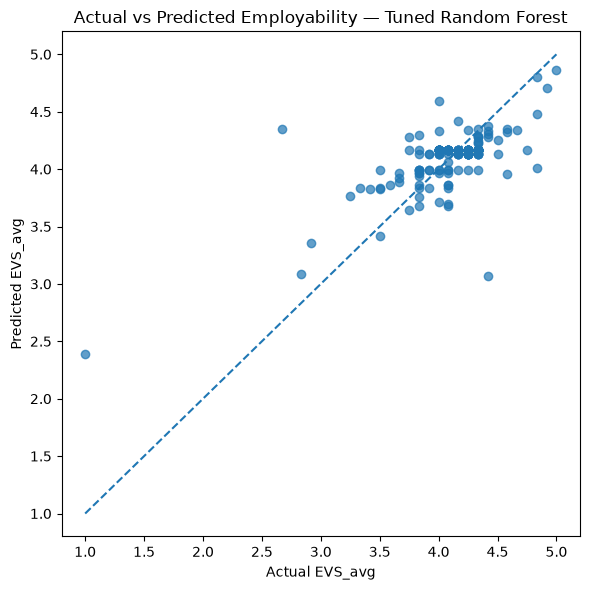

In [38]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

minimum = min(
    y_test.min(),
    best_predictions.min()
)

maximum = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual EVS_avg")
plt.ylabel("Predicted EVS_avg")
plt.title(
    f"Actual vs Predicted Employability — {best_model_name}"
)

plt.tight_layout()
plt.show()

Prediction Error Distribution

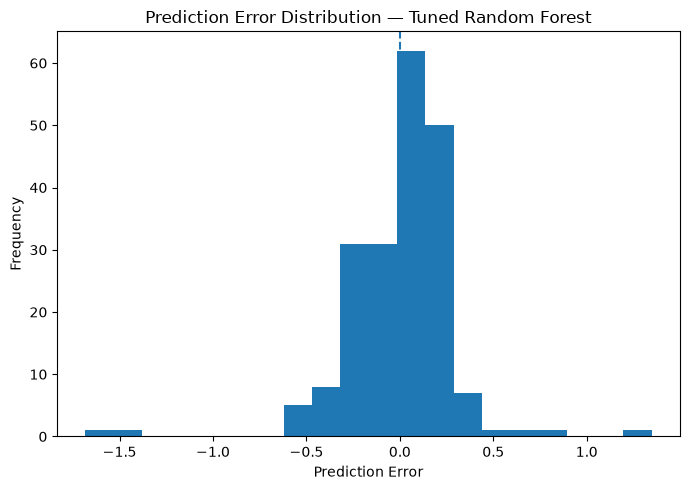

In [39]:
errors = (
    y_test.to_numpy()
    -
    best_predictions
)

plt.figure(figsize=(7, 5))

plt.hist(
    errors,
    bins=20
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title(
    f"Prediction Error Distribution — {best_model_name}"
)

plt.tight_layout()
plt.show()

Prediction Range Check

In [40]:
print(
    "Minimum prediction:",
    best_predictions.min()
)

print(
    "Maximum prediction:",
    best_predictions.max()
)

print(
    "Predictions below 1:",
    np.sum(best_predictions < 1)
)

print(
    "Predictions above 5:",
    np.sum(best_predictions > 5)
)

Minimum prediction: 2.385453116328118
Maximum prediction: 4.861081735484924
Predictions below 1: 0
Predictions above 5: 0


In [41]:
baseline_cv_results.to_csv(
    RESULT_DIR / "Baseline_CV_Results.csv",
    index=False
)

tuned_cv_results.to_csv(
    RESULT_DIR / "Tuned_Model_CV_Results.csv",
    index=False
)

evaluation_results.to_csv(
    RESULT_DIR / "Tuned_Model_Test_Performance.csv",
    index=False
)

tuning_comparison.to_csv(
    RESULT_DIR / "Before_After_Tuning_Comparison.csv",
    index=False
)

final_comparison.to_csv(
    RESULT_DIR / "Final_Tuned_Model_Comparison.csv",
    index=False
)

print("All Step 08 results saved successfully.")

All Step 08 results saved successfully.


Save Best Hyperparameters

In [42]:
best_parameters = {
    "Random_Forest": rf_search.best_params_,
    "SVR": svr_search.best_params_,
    "XGBoost": xgb_search.best_params_,
    "Ridge": ridge_search.best_params_
}

best_parameters

{'Random_Forest': {'n_estimators': 200,
  'min_samples_split': 5,
  'min_samples_leaf': 1,
  'max_features': 'sqrt',
  'max_depth': 5},
 'SVR': {'model__C': 50,
  'model__epsilon': 0.2,
  'model__gamma': 0.01,
  'model__kernel': 'rbf'},
 'XGBoost': {'subsample': 1.0,
  'reg_lambda': 5,
  'reg_alpha': 0.01,
  'n_estimators': 500,
  'min_child_weight': 1,
  'max_depth': 4,
  'learning_rate': 0.01,
  'colsample_bytree': 1.0},
 'Ridge': {'model__alpha': 100}}

In [43]:
import json

with open(
    RESULT_DIR / "Best_Hyperparameters.json",
    "w"
) as f:

    json.dump(
        best_parameters,
        f,
        indent=4
    )

print("Best hyperparameters saved.")

Best hyperparameters saved.


## Step 08 Conclusion

Hyperparameter optimization was performed using cross-validation on the training dataset only, while the held-out test dataset remained isolated during the tuning process.

Random Forest, Support Vector Regression, XGBoost, and Ridge Regression were evaluated using optimized hyperparameter configurations. Linear Regression was retained as a benchmark model.

Model selection considered cross-validation R², cross-validation stability, test R², MAE, RMSE, MAPE, and the difference between training and testing performance.

The best-performing tuned model will be carried forward as the candidate model for subsequent explainability and final validation stages.

Replace the Random Forest final plots with Linear Regression

In [44]:
best_model_name = "Linear Regression"

best_model = tuned_models[best_model_name]

best_model.fit(
    X_train,
    y_train
)

best_predictions = best_model.predict(
    X_test
)

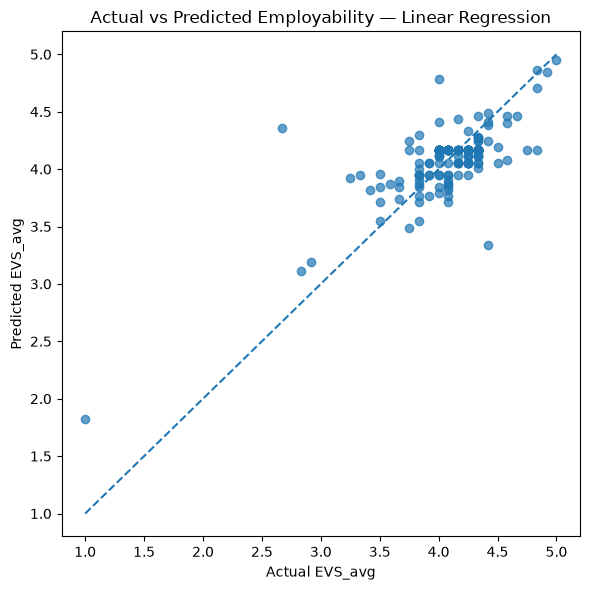

In [45]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

minimum = min(
    y_test.min(),
    best_predictions.min()
)

maximum = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual EVS_avg")
plt.ylabel("Predicted EVS_avg")

plt.title(
    "Actual vs Predicted Employability — Linear Regression"
)

plt.tight_layout()
plt.show()

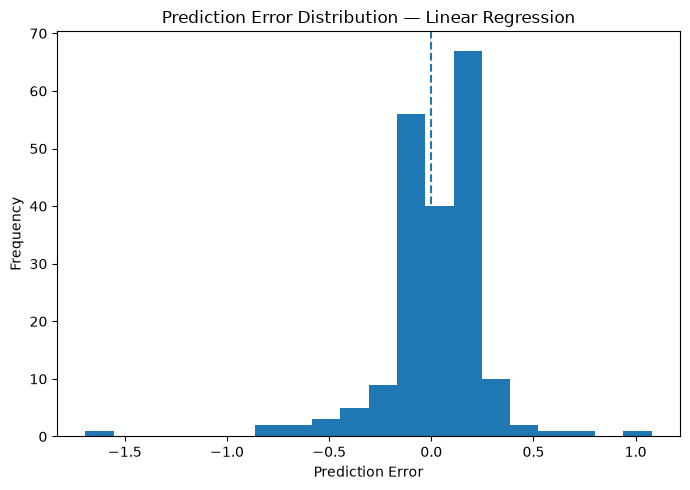

In [46]:
errors = (
    y_test.to_numpy()
    -
    best_predictions
)

plt.figure(figsize=(7, 5))

plt.hist(
    errors,
    bins=20
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.title(
    "Prediction Error Distribution — Linear Regression"
)

plt.tight_layout()
plt.show()

Check Linear Regression prediction range

In [47]:
print(
    "Minimum prediction:",
    best_predictions.min()
)

print(
    "Maximum prediction:",
    best_predictions.max()
)

print(
    "Predictions below 1:",
    np.sum(best_predictions < 1)
)

print(
    "Predictions above 5:",
    np.sum(best_predictions > 5)
)

Minimum prediction: 1.8230715010649359
Maximum prediction: 4.948931547044931
Predictions below 1: 0
Predictions above 5: 0


Add Overfitting Gap to your final table

In [48]:
final_comparison["Overfit_Gap"] = (
    final_comparison["Train_R2"]
    -
    final_comparison["Test_R2"]
)

final_comparison[
    [
        "Model",
        "Train_R2",
        "Test_R2",
        "Mean_CV_R2",
        "Std_CV_R2",
        "MAE",
        "RMSE",
        "MAPE_Percent",
        "Overfit_Gap"
    ]
]

,Model,Train_R2,Test_R2,Mean_CV_R2,Std_CV_R2,MAE,RMSE,MAPE_Percent,Overfit_Gap
3,Tuned SVR,0.610044,0.458114,0.565958,0.070034,0.190249,0.281010,5.429560,0.151930
2,Tuned Random Forest,0.681205,0.484367,0.559218,0.069281,0.184445,0.274118,5.163292,0.196838
4,Tuned XGBoost,0.710775,0.447963,0.554870,0.055967,0.190803,0.283629,5.340321,0.262812
1,Tuned Ridge,0.575122,0.543893,0.548433,0.083182,0.183672,0.257810,4.980866,0.031229
0,Linear Regression,0.576753,0.545732,0.543786,0.097050,0.182397,0.257290,4.907529,0.031021


## Step 08 Conclusion

Hyperparameter tuning was performed using 5-fold cross-validation on the training dataset while preserving the test dataset for independent evaluation.

Tuning improved the cross-validation performance of Random Forest, Support Vector Regression, and XGBoost. Tuned SVR achieved the highest mean cross-validation R² among the optimized nonlinear models.

However, Linear Regression achieved the strongest performance on the held-out test dataset, with the highest test R² and the lowest MAE, RMSE, and MAPE. Linear Regression also demonstrated a small difference between training and testing R², indicating better generalization and lower overfitting compared with the nonlinear alternatives.

Therefore, Linear Regression was retained as the leading candidate model for the subsequent explainability and final validation stages.

## Step 08 Conclusion

Hyperparameter optimization was performed for Random Forest, Support Vector Regression, XGBoost, and Ridge Regression using 5-fold cross-validation on the training dataset. The held-out test dataset was kept separate from the tuning process to provide an independent evaluation of model generalization.

Hyperparameter tuning improved the cross-validation performance of the nonlinear machine learning models. Tuned SVR achieved the highest mean cross-validation R² (0.5660), followed by Tuned Random Forest (0.5592) and Tuned XGBoost (0.5549).

However, Linear Regression achieved the strongest overall performance on the independent test dataset. It produced a test R² of 0.5457, MAE of 0.1824, RMSE of 0.2573, and MAPE of approximately 4.91%.

Linear Regression also demonstrated a small train-test R² gap of approximately 0.031, indicating better generalization and substantially lower overfitting compared with the nonlinear alternatives.

The predicted Employability scores remained within the valid 1–5 range, with no predictions below 1 or above 5.

Therefore, Linear Regression was retained as the leading candidate model for the subsequent explainability, recommendation, and final validation stages.

“I tuned Random Forest, SVR and XGBoost, and their cross-validation scores improved. However, Linear Regression still performed best on the unseen test data, with R² about 0.546, MAPE about 4.91%, and a very small train-test gap. Therefore, I selected Linear Regression as the current best candidate because it generalized better and showed less overfitting.”

Robustness & Stability Validation

The purpose is not to increase R² artificially. It is to prove that your selected Linear Regression result is stable and not dependent on one particular data split.

In [49]:
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import numpy as np

final_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

repeated_scores = cross_val_score(
    final_lr,
    X_train,
    y_train,
    cv=repeated_cv,
    scoring="r2",
    n_jobs=-1
)

print("Repeated CV Mean R²:", repeated_scores.mean())
print("Repeated CV Std R²:", repeated_scores.std())
print("Minimum R²:", repeated_scores.min())
print("Maximum R²:", repeated_scores.max())

Repeated CV Mean R²: 0.5376375821114658
Repeated CV Std R²: 0.1134249364607391
Minimum R²: 0.21602072229491098
Maximum R²: 0.7139710476723875


In [50]:
mean_r2 = repeated_scores.mean()
std_r2 = repeated_scores.std()

lower = mean_r2 - 1.96 * std_r2
upper = mean_r2 + 1.96 * std_r2

print("Mean R²:", mean_r2)
print("Approx. 95% range:", lower, "to", upper)

Mean R²: 0.5376375821114658
Approx. 95% range: 0.31532470664841716 to 0.7599504575745145


. Coefficient Stability Check

In [51]:
coefficient_results = []

for train_idx, val_idx in repeated_cv.split(X_train):

    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    model = LinearRegression()

    model.fit(
        X_fold_train,
        y_fold_train
    )

    coefficient_results.append(
        model.coef_
    )

coefficient_results = np.array(
    coefficient_results
)

coef_stability = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_Coefficient": coefficient_results.mean(axis=0),
    "Std_Coefficient": coefficient_results.std(axis=0)
})

coef_stability

,Feature,Mean_Coefficient,Std_Coefficient
0,LifeCareer_avg,0.219773,0.027759
1,LearningInnovation_avg,0.245965,0.030330
2,ITMedia_avg,0.315911,0.030906
